# Speech to text and word error rate

The farm cooperative's inspectors record voice notes in windy fields, in English, in Russian, or both in one note.
In this notebook you make the same six notes with a text-to-speech voice, add wind, type them with Whisper (the
open speech model, its "tiny" size), and score every transcript with your own `wer` function and with jiwer.
Then you break the night job on purpose and fix it.

About 5 minutes. Free CPU runtime, no account and no key. Run the cells from top to bottom.

## Step 1: install three packages

`openai-whisper` is the Python package that runs Whisper. `jiwer` is an open library that computes word error rate.
`gTTS` reads text aloud with Google Translate's free text-to-speech voice: it plays the inspectors.

**Look for:** the cell finishes without an error. It prints nothing else.

In [1]:
%pip install -q openai-whisper==20250625 jiwer==4.0.0 gTTS==2.5.4

Note: you may need to restart the kernel to use updated packages.


## Step 2: the notes and the references

`SPOKEN` is what each inspector says (numbers as words, as people say them). `REF` is the reference: the same
note typed by a person in the cooperative's style (numbers as digits). WER always compares a transcript with the
reference. Note n6 switches from Russian to English halfway. `LESSON_TX` holds three transcripts that Whisper
"base" (through whisper.cpp) typed in the lesson, copied unchanged.

**Look for:** 6 notes, and 65 reference words in the four English notes.

In [2]:
import random, re
import numpy as np
import torch

random.seed(0); np.random.seed(0); torch.manual_seed(0)

SPOKEN = {   # (language, text) parts, in the order they are spoken
    "n1": [("en", "Plot twelve near Chirchiq. The cotton leaves are curling at the edges, and there are aphids on the lower leaves.")],
    "n2": [("en", "Rows four to nine need spraying on Thursday morning, before the wind picks up.")],
    "n3": [("en", "Apricot orchard in Parkent. Some fruit has brown spots. Take ten samples for the lab.")],
    "n4": [("en", "The wheat field by the canal looks dry. The drip line is blocked near the pump.")],
    "n5": [("ru", "Поле номер семь. Хлопок в хорошем состоянии, но на краю поля много сорняков.")],
    "n6": [("ru", "Поле номер семь. Хлопок в хорошем состоянии."), ("en", "The drip line is blocked near the pump.")],
}
REF = {
    "n1": "Plot 12 near Chirchiq. The cotton leaves are curling at the edges, and there are aphids on the lower leaves.",
    "n2": "Rows 4 to 9 need spraying on Thursday morning, before the wind picks up.",
    "n3": "Apricot orchard in Parkent. Some fruit has brown spots. Take 10 samples for the lab.",
    "n4": "The wheat field by the canal looks dry. The drip line is blocked near the pump.",
    "n5": "Поле номер 7. Хлопок в хорошем состоянии, но на краю поля много сорняков.",
    "n6": "Поле номер 7. Хлопок в хорошем состоянии. The drip line is blocked near the pump.",
}
PROMPT = "Crop inspection notes. Places: Chirchiq, Parkent."
LESSON_TX = {   # whisper.cpp, model base, -l en, from the lesson's runs
    "n2-clean": "Rose 4-9 needs spraying on Thursday morning, before the wind picks up.",
    "n4-clean": "The weed field by the canal looks dry. The drip line is blocked near the pump.",
    "n1-snr5": "The cloth holds near a circuit, the cotton leaves are curling at the edges, and there are aphids on the lower leaves.",
}
EN = ["n1", "n2", "n3", "n4"]
print("notes:", len(SPOKEN))
print("reference words in the English notes:", sum(len(REF[n].split()) for n in EN))

notes: 6
reference words in the English notes: 65


## Step 3: your `wer` function, checked against jiwer

`normalize` puts both texts into one form: lower case, a hyphen becomes a space, no punctuation, number words
become digits. `wer` is the edit-distance table from the lesson, line for line. Then the cell scores the three
lesson transcripts with your function and with `jiwer.wer`, with and without normalizing.

**Look for:** `wer("rows 4 to 9", "rose 4 9")` is 0.5. The rows note has 3 edits in 14 words (0.214) after
normalizing, but 5 edits on the raw texts. Your function and jiwer agree on every line.

In [3]:
import jiwer

def wer(said, typed):
    r, h = said.split(), typed.split()
    n, m = len(r), len(h)
    d = [[0] * (m+1) for _ in range(n+1)]
    for i in range(n+1): d[i][0] = i
    for j in range(m+1): d[0][j] = j
    for i in range(1, n+1):
        for j in range(1, m+1):
            diff = r[i-1] != h[j-1]
            sub = d[i-1][j-1] + diff
            miss = d[i-1][j] + 1
            extra = d[i][j-1] + 1
            d[i][j] = min(sub, miss, extra)
    return d[n][m] / n

NUM = {w: str(i) for i, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}

def normalize(text):
    text = text.lower().replace("-", " ")
    text = re.sub(r"[^\w\s]", "", text)          # drop punctuation (\w keeps Cyrillic letters)
    return " ".join(NUM.get(w, w) for w in text.split())

print('wer("rows 4 to 9", "rose 4 9") =', wer("rows 4 to 9", "rose 4 9"))
for clip, hyp in LESSON_TX.items():
    ref = REF[clip[:2]]
    r, h = normalize(ref), normalize(hyp)
    n_norm, n_raw = len(r.split()), len(ref.split())
    print(f"{clip:9s} normalized: {round(wer(r, h) * n_norm)} edits / {n_norm} words = {wer(r, h):.3f}"
          f"  (jiwer {jiwer.wer(r, h):.3f})   raw: {round(wer(ref, hyp) * n_raw)} edits (jiwer {jiwer.wer(ref, hyp):.3f})")

wer("rows 4 to 9", "rose 4 9") = 0.5
n2-clean  normalized: 3 edits / 14 words = 0.214  (jiwer 0.214)   raw: 5 edits (jiwer 0.357)
n4-clean  normalized: 1 edits / 16 words = 0.062  (jiwer 0.062)   raw: 1 edits (jiwer 0.062)
n1-snr5   normalized: 5 edits / 20 words = 0.250  (jiwer 0.250)   raw: 6 edits (jiwer 0.300)


## Step 4: the inspectors read their notes

The cell asks gTTS to read each note and saves it as an mp3 file. `whisper.load_audio` turns each file into what
Whisper reads: 16,000 numbers per second, one channel. Note n6 is two parts, Russian then English, joined.
The voices are synthetic, like the Mac voices in the lesson, not real inspectors.

**Look for:** six notes, each about 4 to 8 seconds long.

In [4]:
import os
import whisper
from gtts import gTTS

RATE = 16000
os.makedirs("notes_audio", exist_ok=True)

def speak(text, lang, path):
    gTTS(text, lang=lang).save(path)
    return whisper.load_audio(path)          # float32, 16 kHz, mono (uses ffmpeg)

clean = {}
for nid, parts in SPOKEN.items():
    pieces = [speak(text, lang, f"notes_audio/{nid}-{k}.mp3") for k, (lang, text) in enumerate(parts)]
    clean[nid] = np.concatenate(pieces)
    print(nid, f"{len(clean[nid]) / RATE:.1f} s", "+".join(lang for lang, _ in parts))

n1 7.8 s en


n2 5.6 s en


n3 7.1 s en


n4 5.5 s en


n5 7.2 s ru


n6 6.7 s ru+en


## Step 5: add the wind

This is the wind from the lesson's audio script: a low rumble (Brownian noise) with slow gusts and a little hiss,
from a seeded random generator. It is mixed in at a signal-to-noise ratio (SNR) of 10, 5 and 0 dB. At 0 dB the
wind is as loud as the voice. The player lets you hear the windiest version of note n1.

**Look for:** the measured SNR of each n1 clip is the one asked for: 10.0, 5.0, 0.0 dB.

In [5]:
from IPython.display import Audio, display

SNRS = [10, 5, 0]          # dB: lower = windier

def wind(n, rng):
    white = rng.standard_normal(n)
    brown = np.cumsum(white)
    brown -= np.convolve(brown, np.ones(4001) / 4001, mode="same")   # remove the slow drift, keep the rumble
    brown /= np.abs(brown).max()
    t = np.arange(n) / RATE
    gust = 0.6 + 0.4 * np.sin(2 * np.pi * 0.35 * t + rng.uniform(0, 6.28)) ** 2
    hiss = rng.standard_normal(n) * 0.15
    return brown * gust + hiss

def mix(speech, noise, snr):
    p_s, p_n = np.mean(speech ** 2), np.mean(noise ** 2)
    scaled = noise * np.sqrt(p_s / (p_n * 10 ** (snr / 10)))
    return np.clip(speech + scaled, -1, 1).astype(np.float32), scaled

rng = np.random.default_rng(0)
clips, NOISE = {}, {}
for nid, speech in clean.items():
    clips[f"{nid}-clean"] = speech
    NOISE[nid] = wind(len(speech), rng)
    for snr in SNRS:
        clips[f"{nid}-snr{snr}"], scaled = mix(speech, NOISE[nid], snr)
        if nid == "n1":
            print(f"n1-snr{snr}: measured SNR {10 * np.log10(np.mean(speech ** 2) / np.mean(scaled ** 2)):.1f} dB")
print("clips:", len(clips))
display(Audio(clips["n1-snr0"], rate=RATE))

n1-snr10: measured SNR 10.0 dB
n1-snr5: measured SNR 5.0 dB
n1-snr0: measured SNR 0.0 dB


clips: 24


## Step 6: Whisper types its first note

The cell downloads Whisper "tiny" (72 MB) and types the clean wheat-field note with the language set to English.
`temperature=0.0` makes Whisper pick the most likely word each time, so a rerun gives the same text.
`jiwer.process_words` lines the two texts up; `visualize_alignment` prints the line-up with S (substitution),
D (deletion) and I (insertion) under the mistakes.

**Look for:** the transcript, the lined-up words, and the counts. Did the voice note keep "wheat", or did it
turn into another word, as "weed" did in the lesson?

In [6]:
model = whisper.load_model("tiny")

def transcribe(clip, language="en", prompt=None, audio=None):
    audio = clips[clip] if audio is None else audio
    out = model.transcribe(audio, language=language, initial_prompt=prompt, fp16=False, temperature=0.0)
    return out["text"].strip(), out["language"]

def score(note, hyp):
    r, h = normalize(REF[note]), normalize(hyp)
    o = jiwer.process_words(r, h)
    return o, wer(r, h)

hyp, _ = transcribe("n4-clean")
o, w = score("n4", hyp)
print("transcript:", hyp)
print(jiwer.visualize_alignment(o, show_measures=False))
print(f"S={o.substitutions} D={o.deletions} I={o.insertions}  WER = {w:.3f}")

transcript: The wheat field by the canal looks dry. The drip line is block near the pump.
=== SENTENCE 1 ===

REF: the wheat field by the canal looks dry the drip line is blocked near the pump
HYP: the wheat field by the canal looks dry the drip line is   block near the pump
                                                                   S              

S=1 D=0 I=0  WER = 0.062


## Step 7: every English note, every wind level, with and without the prompt

32 transcriptions: 4 notes, 4 wind levels, without and with the prompt that names the two places. For each group
the WER is all edits divided by all reference words (65 per level), as in the lesson. The cell also checks your
`wer` against jiwer on every transcript. It takes about half a minute.

**Look for:** WER goes up from "no wind" to "0 dB" in both rows. Compare the two rows and the totals under
them: did the prompt help tiny on these clips? The n1 lines show how it spelled Chirchiq. The last line says your function matched jiwer on 32 of 32.

In [7]:
import time

LEVELS = ["clean", "snr10", "snr5", "snr0"]
NAMES = {"clean": "no wind", "snr10": "10 dB", "snr5": "5 dB", "snr0": "0 dB"}
t0 = time.time()
rows, same = {}, 0
for setting, prompt in [("plain", None), ("prompt", PROMPT)]:
    for lv in LEVELS:
        edits = words = 0
        for n in EN:
            hyp, _ = transcribe(f"{n}-{lv}", prompt=prompt)
            o, w = score(n, hyp)
            same += abs(w - o.wer) < 1e-12
            edits += o.substitutions + o.deletions + o.insertions
            words += len(normalize(REF[n]).split())
            if n == "n1" and lv == "snr10":
                print(f"n1 at 10 dB, {setting:6s}: {hyp}")
        rows[(setting, lv)] = (edits, words)

print()
print(f"{'tiny':14s}" + "".join(f"{NAMES[lv]:>10s}" for lv in LEVELS))
for setting in ["plain", "prompt"]:
    label = "no prompt" if setting == "plain" else "with prompt"
    print(f"{label:14s}" + "".join(f"{rows[(setting, lv)][0] / rows[(setting, lv)][1]:>10.0%}" for lv in LEVELS))
print(f"\nedits in total: no prompt {sum(rows[('plain', lv)][0] for lv in LEVELS)}, "
      f"with prompt {sum(rows[('prompt', lv)][0] for lv in LEVELS)}")
print(f"your wer() matched jiwer on {same} of {len(EN) * len(LEVELS) * 2} transcripts ({time.time() - t0:.0f} s)")

n1 at 10 dB, plain : Float 12 near church it. The cotton leaves are curling at the edges. And there are aphids on the lower leaves.


n1 at 10 dB, prompt: Plot 12 mere churchx, the cotton leaves are curling at the edges, and there are aphids on the lower leaves.



tiny             no wind     10 dB      5 dB      0 dB
no prompt            12%       17%       26%       54%
with prompt          11%       15%       25%       57%

edits in total: no prompt 71, with prompt 70
your wer() matched jiwer on 32 of 32 transcripts (8 s)


## Step 8: the same numbers as a picture

One line per setting: WER at each wind level.

**Look for:** both lines end higher on the right (the windiest clips) than they start on the left.

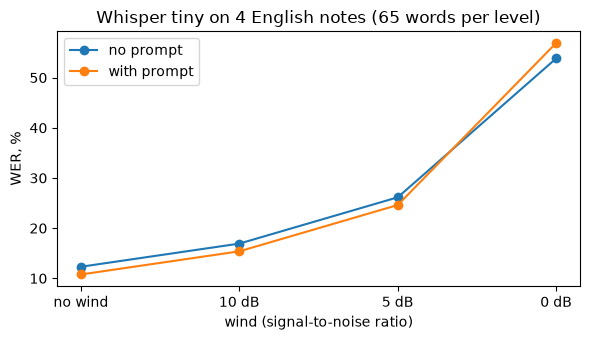

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
for setting, label in [("plain", "no prompt"), ("prompt", "with prompt")]:
    ax.plot([NAMES[lv] for lv in LEVELS], [100 * rows[(setting, lv)][0] / rows[(setting, lv)][1] for lv in LEVELS],
            marker="o", label=label)
ax.set_xlabel("wind (signal-to-noise ratio)")
ax.set_ylabel("WER, %")
ax.set_title("Whisper tiny on 4 English notes (65 words per level)")
ax.legend()
plt.tight_layout()
plt.show()

## Step 9: broken on purpose, the night job

The office's night job ran the same command for every file and never set the language. In whisper-cli (the
program the lesson used) the language then defaults to English. The Python package detects the language when you
leave it out, so here we copy the job's setting by hand: `language="en"` for every file, Russian notes too.

**Look for:** the English notes come out fine. The two Russian clips come out in English letters (no Cyrillic),
and their WER is far above the English notes.

In [9]:
def has_cyrillic(text):
    return bool(re.search("[а-яё]", text.lower()))

print("night job: language='en' for every file")
for clip in ["n1-clean", "n2-clean", "n3-clean", "n4-clean", "n5-clean", "n5-snr10"]:
    hyp, _ = transcribe(clip, language="en")
    o, w = score(clip[:2], hyp)
    print(f"{clip:9s} WER {w:5.0%}  Cyrillic: {has_cyrillic(hyp)!s:5s}  {hyp}")

night job: language='en' for every file


n1-clean  WER    5%  Cyrillic: False  Plot 12 near Churchic, the cotton leaves are curling at the edges. And there are aphids on the lower leaves.


n2-clean  WER   21%  Cyrillic: False  Rose 4-9 needs spraying on Thursday morning before the wind picks up.


n3-clean  WER   20%  Cyrillic: False  Apricot or Chardonn Parkant, some fruit has brown spots. Take ten samples for the lab.


n4-clean  WER    6%  Cyrillic: False  The wheat field by the canal looks dry. The drip line is block near the pump.


n5-clean  WER  138%  Cyrillic: False  Poly No. 7, Hopac in a good condition. But on the edge of Poly No. 7, Poly No. 7,


n5-snr10  WER  108%  Cyrillic: False  The number of the snow is good. But the snow is a new storm.


## Step 10: the fix, let Whisper detect the language

`language=None` tells Whisper to listen to the first 30 seconds and pick the language itself. It returns the
language it picked.

**Look for:** both Russian clips are detected as `ru`, come back in Cyrillic, and their WER drops far below the
numbers in Step 9.

In [10]:
for clip in ["n5-clean", "n5-snr10"]:
    hyp, lang = transcribe(clip, language=None)
    o, w = score("n5", hyp)
    print(f"{clip:9s} detected: {lang}  WER {w:5.0%}  Cyrillic: {has_cyrillic(hyp)}  {hyp}")
print("reference:", REF["n5"])

n5-clean  detected: ru  WER   15%  Cyrillic: True  Поли номер 7 – хлопок в хорошем состоянии, но на краю поли много сорняков.


n5-snr10  detected: ru  WER   46%  Cyrillic: True  Поня номер си, хлопок в хорошем со своем, но на краю поля много сорных опт.
reference: Поле номер 7. Хлопок в хорошем состоянии, но на краю поля много сорняков.


## Step 11: the limit, a note that switches language

Note n6 is Russian, then English. With `language=None`, Whisper detects the language once, from the start of the
clip, and uses it for the whole clip.

**Look for:** with `language="en"` the Russian half turns into English-looking words and the WER is high. With the
language detected (`ru`), see whether the English half survived. In the lesson, whisper.cpp with base dropped it.
If tiny keeps it here, that is luck, not a rule: score mixed notes as their own group.

In [11]:
for language in [None, "en"]:
    hyp, lang = transcribe("n6-clean", language=language)
    o, w = score("n6", hyp)
    print(f"language={language!s:4s} used: {lang}  WER {w:5.0%}  {hyp}")
print("reference:", REF["n6"])

language=None used: ru  WER   13%  Поли номер 7. Хлопок в хорошем состоянии. The drip line is black near the pump.


language=en   used: en  WER   53%  Polynummer 7 Hopax in the good condition The drip line is black near the pump
reference: Поле номер 7. Хлопок в хорошем состоянии. The drip line is blocked near the pump.


## Now change it

Each cell below has one line marked `# <- change this`. Edit it, run the cell, and compare with the output that
is there now.

**1. More wind.** Set `WIND_DB` to -5 (the wind is louder than the voice). The WER of note n1 should rise above
the value the cell prints now at 0 dB, because more of the voice is covered.

In [12]:
WIND_DB = 0          # <- change this
audio, _ = mix(clean["n1"], NOISE["n1"], WIND_DB)
hyp, _ = transcribe("n1", audio=audio)
o, w = score("n1", hyp)
print(f"n1 at {WIND_DB} dB: WER {w:.0%}  {hyp}")

n1 at 0 dB: WER 35%  The spot swells near church, the cotton leaves are curling at the edge. And there are 8 bits on the lower leaves.


**2. A prompt without the place names.** Set `MY_PROMPT` to `"Crop inspection notes."`. On the notes with
Chirchiq and Parkent, the place names should be spelled wrong more often, because the prompt is the only place
the model can learn how they are written.

In [13]:
MY_PROMPT = "Crop inspection notes. Places: Chirchiq, Parkent."     # <- change this
for clip in ["n1-clean", "n1-snr10", "n3-clean", "n3-snr10"]:
    hyp, _ = transcribe(clip, prompt=MY_PROMPT)
    o, w = score(clip[:2], hyp)
    print(f"{clip:9s} WER {w:4.0%}  {hyp}")

n1-clean  WER   5%  Plot 12 near Chirchic, the cotton leaves are curling at the edges. And there are aphids on the lower leaves.


n1-snr10  WER  10%  Plot 12 mere churchx, the cotton leaves are curling at the edges, and there are aphids on the lower leaves.


n3-clean  WER  13%  Apricot or Chirchiq in Parkent, some fruit has brown spots. Take ten samples for the lab.


n3-snr10  WER  27%  Africa, oratured and parking. Some fruit has brown spots. Take ten samples for the lab.


**3. The wrong fix.** Set `LANG` to `"ru"`, as if the night job forced Russian on every file. The English
wheat-field note should come back partly or fully in Cyrillic with a high WER: forcing one language breaks the
notes in the other one.

In [14]:
LANG = "en"          # <- change this
hyp, _ = transcribe("n4-clean", language=LANG)
o, w = score("n4", hyp)
print(f"n4-clean with language={LANG}: WER {w:.0%}  Cyrillic: {has_cyrillic(hyp)}  {hyp}")

n4-clean with language=en: WER 6%  Cyrillic: False  The wheat field by the canal looks dry. The drip line is block near the pump.


## What you should see

These are the same items as on the lesson's last screen.

- Step 3: `wer("rows 4 to 9", "rose 4 9")` prints 0.5, and the whole rows note scores 3 edits / 14 words = 0.214.
- Your `wer` gives the same number as `jiwer.wer` on every transcript: Step 7 prints 32 of 32.
- Step 3: without normalizing (the raw texts split on spaces), the rows note has 5 edits instead of 3.
- Step 9: the Russian note with `language="en"` comes back with no Cyrillic text. Step 10: with the language
  detected, it is `ru` and comes back in Cyrillic.
- Step 7: WER rises as the wind gets louder: both rows of the table are much higher at 0 dB than with no wind.